<a href="https://colab.research.google.com/github/AmirthaaR/Object_Detection_YOLO/blob/main/Object_Detection_YOLO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## *Cell 1 — Install YOLO*

In [1]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 10.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


*Cell 2 — Import libraries and load model*

In [2]:
from ultralytics import YOLO
from google.colab import files
from IPython.display import Image, display
import cv2
import matplotlib.pyplot as plt

model = YOLO("yolo11n.pt")
print("YOLO model loaded successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLO model loaded successfully!


*Cell 3 — Upload an image*

In [3]:
uploaded = files.upload()
image_path = next(iter(uploaded))
print("Uploaded image:", image_path)

Saving crowded street photo.jpg to crowded street photo.jpg
Uploaded image: crowded street photo.jpg


*Cell 4 — Detect objects*

In [4]:
results = model.predict(source=image_path, conf=0.25, save=True)
result = results[0]

print("Objects detected:", len(result.boxes))


image 1/1 /content/crowded street photo.jpg: 448x640 9 persons, 2 cars, 3 motorcycles, 1 truck, 324.0ms
Speed: 25.0ms preprocess, 324.0ms inference, 37.7ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict
Objects detected: 15


*Cell 5 — Display the detected image*

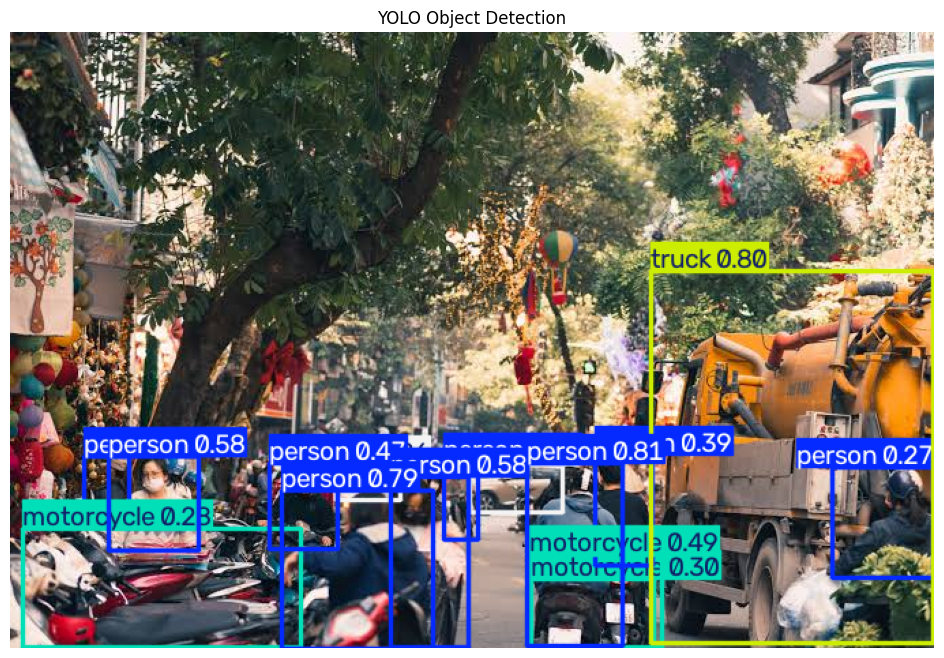

In [5]:
annotated_image = result.plot()
annotated_image = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(annotated_image)
plt.axis("off")
plt.title("YOLO Object Detection")
plt.show()

*Cell 6 — Display detected object names and confidence scores*

In [6]:
for box in result.boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    confidence = float(box.conf[0])
    print(f"{name}: {confidence:.2%}")

person: 81.33%
truck: 79.72%
person: 79.08%
person: 58.46%
person: 58.05%
motorcycle: 49.17%
person: 47.49%
person: 39.46%
motorcycle: 29.51%
person: 28.78%
motorcycle: 27.89%
person: 27.22%
person: 27.18%
car: 26.27%
car: 25.57%


*Cell 7 — Download the output image*

In [7]:
output_path = str(result.save(filename="detected_objects.jpg"))
files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

*Cell 8 — Save the model information*

In [8]:
print("Model: YOLO11 Nano")
print("Task: Object Detection")
print("Confidence threshold: 0.25")
print("Total objects detected:", len(result.boxes))

Model: YOLO11 Nano
Task: Object Detection
Confidence threshold: 0.25
Total objects detected: 15
